# Домашняя работа 2

## Регрессия

С 1 октября отменяется НДС на бриллианты, теперь они становятся новым инвестиционным инструментом. Давайте сделаем модель ценообразования для них.

Скачайте датасет diamonds.csv

В нем представлены характеристики бриллиантов и их цены с сайта jamesallen (B2C площадка) с 2022-07-01

**Описание полей**


* fluor - флуорисценция (свойство камня светиться в лучах ультр)
* symmetry - показатель симметричности
* platform - название платформы, где был размещен камень
* quality_group - составной показатель из cut polish symmetry
* size_group - каратно-весовая группа
* big_size_group - каратно-весовая группа
* shape - форма
* color - цвет
* clarity - чистота
* cut - качество огранки (может быть только у круглых камней)
* polish - полировка
* id - номер камня
* date - дата
* price - цена
* carat - кол-во карат
* tablepercent - размер площадки по отношению ширине
* price_per_carat - цена за карат
* z - длина (diameter)
* x - ширина
* depth_perc - отношение высоты к ширине
* y - высота

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.core.pylabtools import figsize

Загрузим и прочитаем файлы

In [2]:
df = pd.read_csv('diamonds.csv', index_col=0)
df

,fluor,symmetry,platform,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,x,depth_perc,y
135269,NONE,EX,jamesallen,PS,F,SI1,NaN,EX,13870838,202206,12850.0,1.55,8290.32,10.29,6.41,62.0,3.97420
48477,MED,EX,jamesallen,RD,H,VVS2,EX,EX,11725253,202207,7510.0,1.02,7362.75,6.41,6.45,62.5,4.03125
236786,NONE,EX,jamesallen,EM,H,IF,NaN,EX,14444347,202205,21220.0,2.01,10557.21,8.60,6.37,65.0,4.14050
235781,NONE,EX,jamesallen,RD,E,VS2,EX,EX,14438434,202207,8660.0,1.00,8660.00,6.39,6.44,61.4,3.95416
277744,NONE,VG,jamesallen,RD,F,VS1,VG,EX,14615276,202206,8480.0,1.00,8480.00,6.28,6.36,62.3,3.96228
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20595,NONE,EX,jamesallen,RD,D,VS2,EX,EX,7535786,202207,8700.0,0.97,8969.07,6.36,6.32,62.2,3.93104
282754,NONE,EX,jamesallen,RD,D,VS2,EX,EX,14631732,202206,6650.0,0.90,7388.89,6.13,6.18,61.7,3.81306
141550,NONE,EX,jamesallen,RD,J,SI2,EX,EX,13932645,202205,11570.0,1.52,7611.84,7.36,7.39,61.0,4.50790
71237,STG,EX,jamesallen,RD,G,VS1,EX,EX,12699310,202207,8220.0,1.09,7541.28,6.55,6.60,62.0,4.09200


Необходимо предсказать `price_per_carat`

In [3]:
# посмотрим на размеры датасета
df.shape

(222222, 17)

In [ ]:
# посмотрим, какие значения принимает столбец 'id'
df.sort_values(by = ['id'])

,fluor,symmetry,platform,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,x,depth_perc,y
53948,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0.0,0.00,0.00,0.00,0.00,0.0,0.00000
202754,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0.0,0.00,0.00,0.00,0.00,0.0,0.00000
244620,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0.0,0.00,0.00,0.00,0.00,0.0,0.00000
53946,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0.0,0.00,0.00,0.00,0.00,0.0,0.00000
7,NONE,EX,jamesallen,RD,D,VVS2,EX,EX,19423,202207,14550.0,1.05,13857.14,6.67,6.64,59.7,3.96408
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
453622,NONE,EX,jamesallen,PS,I,SI1,NaN,EX,15418480,202207,3570.0,1.01,3534.65,8.76,5.31,65.4,3.47274
453623,FNT,VG,jamesallen,OV,H,SI1,NaN,EX,15418482,202207,4180.0,1.00,4180.00,7.67,5.49,65.5,3.59595
453625,STG,EX,jamesallen,RD,I,VS2,EX,EX,15418486,202207,6970.0,1.20,5808.33,6.72,6.77,62.7,4.24479
453628,NONE,VG,jamesallen,PR,F,VS2,EX,EX,15418493,202207,10470.0,1.50,6980.00,6.58,6.33,73.2,4.63356


In [ ]:
# кажется столбец 'platform' принимает только одно значение
df[df['platform'] != 'jamesallen']

,fluor,symmetry,platform,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,x,depth_perc,y
202754,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
244620,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
53946,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
53948,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# удаляем пустые строки
df = df.drop([202754, 244620, 53946, 53948])
df

,fluor,symmetry,platform,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,x,depth_perc,y
135269,NONE,EX,jamesallen,PS,F,SI1,NaN,EX,13870838,202206,12850.0,1.55,8290.32,10.29,6.41,62.0,3.97420
48477,MED,EX,jamesallen,RD,H,VVS2,EX,EX,11725253,202207,7510.0,1.02,7362.75,6.41,6.45,62.5,4.03125
236786,NONE,EX,jamesallen,EM,H,IF,NaN,EX,14444347,202205,21220.0,2.01,10557.21,8.60,6.37,65.0,4.14050
235781,NONE,EX,jamesallen,RD,E,VS2,EX,EX,14438434,202207,8660.0,1.00,8660.00,6.39,6.44,61.4,3.95416
277744,NONE,VG,jamesallen,RD,F,VS1,VG,EX,14615276,202206,8480.0,1.00,8480.00,6.28,6.36,62.3,3.96228
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20595,NONE,EX,jamesallen,RD,D,VS2,EX,EX,7535786,202207,8700.0,0.97,8969.07,6.36,6.32,62.2,3.93104
282754,NONE,EX,jamesallen,RD,D,VS2,EX,EX,14631732,202206,6650.0,0.90,7388.89,6.13,6.18,61.7,3.81306
141550,NONE,EX,jamesallen,RD,J,SI2,EX,EX,13932645,202205,11570.0,1.52,7611.84,7.36,7.39,61.0,4.50790
71237,STG,EX,jamesallen,RD,G,VS1,EX,EX,12699310,202207,8220.0,1.09,7541.28,6.55,6.60,62.0,4.09200


In [ ]:
# такой параметр камня как отношение высоты к ширине не должен меняться со временем
df.depth_perc.describe()

count    222218.000000
mean         64.087981
std           4.191885
min          46.000000
25%          61.800000
50%          63.000000
75%          66.000000
max          78.000000
Name: depth_perc, dtype: float64

### Задание 1: Очистка

Не все камни успевают продаться за один месяц, поэтому в таблице есть повторы. Объедините данные по одному камню: подумайте, как лучше это сделать, какую цену брать.

**Попробуйте найти аномалии:** вдруг цена на некоторые камни сильно меняется (то есть продавец сам не знает, по какой цене их продавать). Также убедитесь, что остальные параметры камня не меняются.

In [ ]:
id_stat = df.groupby(by='id')['carat'].count().to_frame() #Посчитайте статистику по кол-ву камней
id_stat

,carat
id,
19423,3
19449,2
19476,1
19501,3
19504,2
...,...
15418480,1
15418482,1
15418486,1


In [ ]:
# подготавливаем датасет для выборки
df_new = pd.merge(df, id_stat, on='id')
df_new.rename(columns={'carat_x': 'carat', 'carat_y': 'count'}, inplace=True)

In [ ]:
# разделите выборку на две части

df_one = df_new.query('count == 1')  # те камни, которые встречались один раз
df_three = df_new.query('count > 1 & count < 4') # те камни, которые встречались 2 или 3 раза
#df_one.head()
df_three


,fluor,symmetry,platform,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,x,depth_perc,y,count
0,NONE,EX,jamesallen,PS,F,SI1,NaN,EX,13870838,202206,12850.0,1.55,8290.32,10.29,6.41,62.0,3.97420,2
1,NONE,EX,jamesallen,PS,F,SI1,NaN,EX,13870838,202207,13380.0,1.55,8632.26,10.29,6.41,62.0,3.97420,2
2,MED,EX,jamesallen,RD,H,VVS2,EX,EX,11725253,202207,7510.0,1.02,7362.75,6.41,6.45,62.5,4.03125,3
3,MED,EX,jamesallen,RD,H,VVS2,EX,EX,11725253,202206,7410.0,1.02,7264.71,6.41,6.45,62.5,4.03125,3
4,MED,EX,jamesallen,RD,H,VVS2,EX,EX,11725253,202205,7520.0,1.02,7372.55,6.41,6.45,62.0,3.99900,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
221251,NONE,EX,jamesallen,OV,F,SI2,NaN,EX,14559657,202205,3410.0,1.00,3410.00,7.84,5.75,60.0,3.45000,2
221410,MED,VG,jamesallen,RD,F,I1,VG,VG,14268340,202206,15820.0,2.02,7831.68,7.95,8.07,61.6,4.97112,2
221411,MED,VG,jamesallen,RD,F,I1,VG,VG,14268340,202207,16470.0,2.02,8153.47,7.95,8.07,61.6,4.97112,2
221947,NONE,VG,jamesallen,HS,E,VVS1,NaN,EX,14424790,202205,6750.0,1.00,6750.00,5.89,6.48,61.0,3.95280,2


In [ ]:
df_one

,fluor,symmetry,platform,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,x,depth_perc,y,count
15,NONE,EX,jamesallen,PS,D,SI2,NaN,EX,14224443,202205,9120.0,1.51,6039.74,10.67,6.23,59.0,3.67570,1
16,NONE,VG,jamesallen,EM,K,SI2,NaN,VG,12902293,202205,1390.0,0.91,1527.47,6.30,4.58,71.0,3.25180,1
19,NONE,VG,jamesallen,PS,J,VS1,NaN,VG,12771762,202207,15990.0,2.27,7044.05,11.66,7.26,62.2,4.51572,1
20,MED,EX,jamesallen,RD,J,SI2,EX,EX,14584509,202205,3700.0,1.01,3663.37,6.37,6.42,62.0,3.98040,1
21,NONE,EX,jamesallen,RD,G,SI1,EX,EX,14773748,202206,7170.0,1.00,7170.00,6.30,6.35,63.7,4.04495,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
222213,NONE,EX,jamesallen,RD,F,IF,EX,EX,15296246,202207,20250.0,1.30,15576.92,7.03,7.08,60.8,4.30464,1
222214,NONE,EX,jamesallen,RD,I,VS2,EX,EX,15037555,202206,8980.0,1.35,6651.85,7.05,7.09,61.7,4.37453,1
222215,STG,G,jamesallen,CUSH,H,SI2,VG,VG,14102502,202205,2970.0,1.01,2940.59,6.12,5.31,71.0,3.77010,1
222216,NONE,EX,jamesallen,RD,J,SI2,EX,EX,13932645,202205,11570.0,1.52,7611.84,7.36,7.39,61.0,4.50790,1


In [ ]:
stat = df_three.groupby('id')[['price', 'price_per_carat', 'carat', 'z', 'x', 'depth_perc', 'y']].agg(np.std) # Посчитайте стандартное отклонение по нескольким полям,
#  подумайте где оно должно равняться 0, а где меняться в каких-то разумных пределах
stat

,price,price_per_carat,carat,z,x,depth_perc,y
id,,,,,,,
19423,334.863156,318.916742,0.0,0.0,0.0,0.404145,0.026835
19449,494.974747,423.054916,0.0,0.0,0.0,0.000000,0.000000
19501,831.384388,415.692194,0.0,0.0,0.0,0.346410,0.027436
19504,0.000000,0.000000,0.0,0.0,0.0,0.212132,0.014213
19505,813.172798,404.564074,0.0,0.0,0.0,0.353553,0.028602
...,...,...,...,...,...,...,...
15409696,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000
15410303,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000
15410668,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000


In [ ]:
# убывающая сортировка отклонений по параметру, который не должен меняться для одного и того же камня
stat.sort_values(by=['depth_perc'], ascending=False)

,price,price_per_carat,carat,z,x,depth_perc,y
id,,,,,,,
14408689,106.066017,582.182226,0.070711,0.035355,0.056569,1.909188,0.154128
14020956,236.713610,525.141309,0.034641,0.005774,0.005774,1.039230,0.069213
14104780,777.817459,487.599623,0.021213,0.028284,0.028284,0.848528,0.057502
14579436,0.000000,0.000000,0.000000,0.056569,0.035355,0.707107,0.072973
4385626,1414.213562,352.669507,0.000000,0.000000,0.000000,0.636396,0.053967
...,...,...,...,...,...,...,...
13301597,84.852814,94.278547,0.000000,0.000000,0.000000,0.000000,0.000000
14607443,367.695526,245.132708,0.000000,0.000000,0.000000,0.000000,0.000000
13301875,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [ ]:
# избавимся от странных изменений по физическим параметрам

stat = stat[(stat['depth_perc'] == 0)]


In [ ]:
stat = stat[(stat['y'] == 0)]


In [ ]:
stat = stat[(stat['x'] == 0)]


In [ ]:
stat = stat[(stat['z'] == 0)]

In [ ]:
stat

,price,price_per_carat,carat,z,x,depth_perc,y
id,,,,,,,
19449,494.974747,423.054916,0.0,0.0,0.0,0.0,0.0
19507,770.746391,379.673915,0.0,0.0,0.0,0.0,0.0
19518,1223.294731,579.756850,0.0,0.0,0.0,0.0,0.0
19635,127.017059,124.522906,0.0,0.0,0.0,0.0,0.0
19656,155.563492,145.381154,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...
15409696,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
15410303,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
15410668,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0


Из 50 373 уникальных наименований осталось 20 007 без отклонений и ошибок по физическим параметрам

In [ ]:
# убывающая сортировка отклонений по параметру, который не должен меняться для одного и того же камня. Все удалены
stat.sort_values(by=['z'], ascending=False).head(10)

,price,price_per_carat,carat,z,x,depth_perc,y
id,,,,,,,
19449,494.974747,423.054916,0.0,0.0,0.0,0.0,0.0
14804280,367.695526,350.187562,0.0,0.0,0.0,0.0,0.0
14805121,169.705627,67.882251,0.0,0.0,0.0,0.0,0.0
14805049,84.852814,84.852814,0.0,0.0,0.0,0.0,0.0
14805000,56.568542,56.568542,0.0,0.0,0.0,0.0,0.0
14804954,35.355339,35.001786,0.0,0.0,0.0,0.0,0.0
14804329,516.187950,258.093975,0.0,0.0,0.0,0.0,0.0
14804315,459.619408,302.387144,0.0,0.0,0.0,0.0,0.0
14804288,98.994949,97.050406,0.0,0.0,0.0,0.0,0.0


In [ ]:
# сформируем наш датасет без аномалий
df_three = df_three[df_three.id.isin(stat.index)] 

In [ ]:
df_three

,fluor,symmetry,platform,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,x,depth_perc,y,count
0,NONE,EX,jamesallen,PS,F,SI1,NaN,EX,13870838,202206,12850.0,1.55,8290.32,10.29,6.41,62.0,3.97420,2
1,NONE,EX,jamesallen,PS,F,SI1,NaN,EX,13870838,202207,13380.0,1.55,8632.26,10.29,6.41,62.0,3.97420,2
17,NONE,VG,jamesallen,RD,D,VS2,EX,VG,4666424,202207,19150.0,1.51,12682.12,7.31,7.27,62.4,4.53648,2
18,NONE,VG,jamesallen,RD,D,VS2,EX,VG,4666424,202206,18400.0,1.51,12185.43,7.31,7.27,62.4,4.53648,2
22,NONE,VG,jamesallen,RD,I,VVS2,VG,EX,12693844,202207,5630.0,1.00,5630.00,6.22,6.30,64.0,4.03200,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
221070,NONE,EX,jamesallen,RD,E,VS1,EX,EX,14327684,202207,11570.0,1.01,11455.45,6.40,6.44,61.6,3.96704,2
221096,NONE,VG,jamesallen,EM,I,VVS2,NaN,EX,14747413,202206,9220.0,1.51,6105.96,7.47,5.54,66.6,3.68964,2
221097,NONE,VG,jamesallen,EM,I,VVS2,NaN,EX,14747413,202207,9600.0,1.51,6357.62,7.47,5.54,66.6,3.68964,2
221410,MED,VG,jamesallen,RD,F,I1,VG,VG,14268340,202206,15820.0,2.02,7831.68,7.95,8.07,61.6,4.97112,2


In [ ]:
df_my = df_three.set_index(['id', 'date']) # здесь видно изменение цен по каждому камню; в процессе поиска моей инфляции
df_my

fluor symmetry    platform shape color clarity  cut polish  \
id       date                                                                
13870838 202206  NONE       EX  jamesallen    PS     F     SI1  NaN     EX   
         202207  NONE       EX  jamesallen    PS     F     SI1  NaN     EX   
4666424  202207  NONE       VG  jamesallen    RD     D     VS2   EX     VG   
         202206  NONE       VG  jamesallen    RD     D     VS2   EX     VG   
12693844 202207  NONE       VG  jamesallen    RD     I    VVS2   VG     EX   
...               ...      ...         ...   ...   ...     ...  ...    ...   
14327684 202207  NONE       EX  jamesallen    RD     E     VS1   EX     EX   
14747413 202206  NONE       VG  jamesallen    EM     I    VVS2  NaN     EX   
         202207  NONE       VG  jamesallen    EM     I    VVS2  NaN     EX   
14268340 202206   MED       VG  jamesallen    RD     F      I1   VG     VG   
         202207   MED       VG  jamesallen    RD     F      I1   VG     VG   

                   price  carat  price_per_carat      z     x  depth_perc  \
id       date                                                               
13870838 202206  12850.0   1.55          8290.32  10.29  6.41        62.0   
         202207  13380.0   1.55          8632.26  10.29  6.41        62.0   
4666424  202207  19150.0   1.51         12682.12   7.31  7.27        62.4   
         202206  18400.0   1.51         12185.43   7.31  7.27        62.4   
12693844 202207   5630.0   1.00          5630.00   6.22  6.30        64.0   
...                  ...    ...              ...    ...   ...         ...   
14327684 202207  11570.0   1.01         11455.45   6.40  6.44        61.6   
14747413 202206   9220.0   1.51          6105.96   7.47  5.54        66.6   
         202207   9600.0   1.51          6357.62   7.47  5.54        66.6   
14268340 202206  15820.0   2.02          7831.68   7.95  8.07        61.6   
         202207  16470.0   2.02          8153.47   7.95  8.07        61.6   

                       y  count  
id       date                    
13870838 202206  3.97420      2  
         202207  3.97420      2  
4666424  202207  4.53648      2  
         202206  4.53648      2  
12693844 202207  4.03200      2  
...                  ...    ...  
14327684 202207  3.96704      2  
14747413 202206  3.68964      2  
         202207  3.68964      2  
14268340 202206  4.97112      2  
         202207  4.97112      2  

[41256 rows x 16 columns]

In [ ]:
# выкинем повторяющиеся записи
df_my = df_my.drop_duplicates()
df_my

fluor symmetry    platform shape color clarity  cut polish  \
id       date                                                                
13870838 202206  NONE       EX  jamesallen    PS     F     SI1  NaN     EX   
         202207  NONE       EX  jamesallen    PS     F     SI1  NaN     EX   
4666424  202207  NONE       VG  jamesallen    RD     D     VS2   EX     VG   
         202206  NONE       VG  jamesallen    RD     D     VS2   EX     VG   
12693844 202207  NONE       VG  jamesallen    RD     I    VVS2   VG     EX   
...               ...      ...         ...   ...   ...     ...  ...    ...   
14327684 202207  NONE       EX  jamesallen    RD     E     VS1   EX     EX   
14747413 202206  NONE       VG  jamesallen    EM     I    VVS2  NaN     EX   
         202207  NONE       VG  jamesallen    EM     I    VVS2  NaN     EX   
14268340 202206   MED       VG  jamesallen    RD     F      I1   VG     VG   
         202207   MED       VG  jamesallen    RD     F      I1   VG     VG   

                   price  carat  price_per_carat      z     x  depth_perc  \
id       date                                                               
13870838 202206  12850.0   1.55          8290.32  10.29  6.41        62.0   
         202207  13380.0   1.55          8632.26  10.29  6.41        62.0   
4666424  202207  19150.0   1.51         12682.12   7.31  7.27        62.4   
         202206  18400.0   1.51         12185.43   7.31  7.27        62.4   
12693844 202207   5630.0   1.00          5630.00   6.22  6.30        64.0   
...                  ...    ...              ...    ...   ...         ...   
14327684 202207  11570.0   1.01         11455.45   6.40  6.44        61.6   
14747413 202206   9220.0   1.51          6105.96   7.47  5.54        66.6   
         202207   9600.0   1.51          6357.62   7.47  5.54        66.6   
14268340 202206  15820.0   2.02          7831.68   7.95  8.07        61.6   
         202207  16470.0   2.02          8153.47   7.95  8.07        61.6   

                       y  count  
id       date                    
13870838 202206  3.97420      2  
         202207  3.97420      2  
4666424  202207  4.53648      2  
         202206  4.53648      2  
12693844 202207  4.03200      2  
...                  ...    ...  
14327684 202207  3.96704      2  
14747413 202206  3.68964      2  
         202207  3.68964      2  
14268340 202206  4.97112      2  
         202207  4.97112      2  

[38292 rows x 16 columns]

In [ ]:
inf_3_m = df_my.copy()
inf_3_m.sort_values(by = 'price')

fluor symmetry    platform shape color clarity  cut polish  \
id       date                                                                
13133377 202206   STG       VG  jamesallen    EM     K      I1  NaN     VG   
         202207   STG       VG  jamesallen    EM     K      I1  NaN     VG   
12001016 202206  NONE       EX  jamesallen    RD     M     SI2   EX     EX   
12197594 202206   FNT       VG  jamesallen    EM     H      I1  NaN     EX   
12001016 202207  NONE       EX  jamesallen    RD     M     SI2   EX     EX   
...               ...      ...         ...   ...   ...     ...  ...    ...   
14914380 202207  NONE       EX  jamesallen    RD     D     SI2   EX     EX   
14125986 202207  NONE       EX  jamesallen    RD     E     VS1   EX     EX   
13215429 202207  NONE       EX  jamesallen    RD     G      IF   EX     EX   
2839630  202205  NONE       EX  jamesallen    RD     E    VVS1   EX     EX   
         202207  NONE       EX  jamesallen    RD     E    VVS1   EX     EX   

                     price  carat  price_per_carat      z      x  depth_perc  \
id       date                                                                  
13133377 202206     1100.0   0.90          1222.22   6.66   4.57        65.6   
         202207     1120.0   0.90          1244.44   6.66   4.57        65.6   
12001016 202206     1140.0   0.81          1407.41   5.92   5.95        62.9   
12197594 202206     1160.0   0.90          1288.89   5.88   4.59        72.0   
12001016 202207     1170.0   0.81          1444.44   5.92   5.95        62.9   
...                    ...    ...              ...    ...    ...         ...   
14914380 202207  1264490.0  21.17         59730.28  17.96  18.05        59.5   
14125986 202207  1278240.0  18.07         70738.24  17.06  17.10        60.2   
13215429 202207  1335060.0  15.01         88944.70  16.19  16.28        58.6   
2839630  202205  2286110.0  20.28        112727.32  17.66  17.57        61.0   
         202207  2380380.0  20.28        117375.74  17.66  17.57        61.0   

                         y  count  
id       date                      
13133377 202206   2.997920      2  
         202207   2.997920      2  
12001016 202206   3.742550      2  
12197594 202206   3.304800      2  
12001016 202207   3.742550      2  
...                    ...    ...  
14914380 202207  10.739750      2  
14125986 202207  10.294201      2  
13215429 202207   9.540080      2  
2839630  202205  10.717700      3  
         202207  10.717700      3  

[38292 rows x 16 columns]

In [ ]:
inf_3_m = inf_3_m[['price_per_carat']]
inf_3_m.sort_values(by = 'id')
# отбираем один столбец для расчета инфляции

price_per_carat
id       date                   
19449    202207         15000.00
         202205         14401.71
19507    202207         13576.35
         202206         13039.41
19518    202206         19867.30
...                          ...
15409696 202207          5980.20
15410303 202207          6554.46
15410668 202207          9833.33
15410717 202207         10646.80
15412954 202207          5916.67

[38292 rows x 1 columns]

In [ ]:
# три даты = май, июнь, июль переходят в колонки, мы видим, что были ошибки и не везде есть данные по трем разным месяцам
inf_3_m = inf_3_m.unstack(level=1)
inf_3_m

price_per_carat                    
date              202205    202206    202207
id                                          
13870838             NaN   8290.32   8632.26
4666424              NaN  12185.43  12682.12
12693844             NaN   5580.00   5630.00
15389091             NaN       NaN  12096.00
14380849             NaN   6060.00   6070.00
...                  ...       ...       ...
14276845         8567.25       NaN       NaN
15355683             NaN       NaN  16721.43
14327684             NaN  11336.63  11455.45
14747413             NaN   6105.96   6357.62
14268340             NaN   7831.68   8153.47

[20006 rows x 3 columns]

In [ ]:
# посмотрим, сколько останется данных с действительным изменением цены по всем трём датам
pure_3_inf = inf_3_m.dropna()
pure_3_inf

price_per_carat                  
date              202205   202206   202207
id                                        
14147975         8237.62  8049.50  8019.80
13576026         4530.00  4430.00  4500.00
14772174         9529.80  9576.16  9662.25
14031297         4420.00  4775.00  4970.00
14694570         5690.00  5590.00  5710.00
...                  ...      ...      ...
12570590         2574.26  2683.17  2712.87
14419797         4280.00  4380.00  4560.00
14115557         4154.76  4047.62  4095.24
14188547         5422.22  5311.11  5455.56
8280674          4165.14  4339.45  4614.68

[340 rows x 3 columns]

In [ ]:
pure_3_inf = pure_3_inf.rename(columns={"price_per_carat": "pricechange"})
pure_3_inf

pricechange                  
date          202205   202206   202207
id                                    
14147975     8237.62  8049.50  8019.80
13576026     4530.00  4430.00  4500.00
14772174     9529.80  9576.16  9662.25
14031297     4420.00  4775.00  4970.00
14694570     5690.00  5590.00  5710.00
...              ...      ...      ...
12570590     2574.26  2683.17  2712.87
14419797     4280.00  4380.00  4560.00
14115557     4154.76  4047.62  4095.24
14188547     5422.22  5311.11  5455.56
8280674      4165.14  4339.45  4614.68

[340 rows x 3 columns]

Итого, инфляцию на основании изменений за три месяца нам могут показать всего 340 записей 

In [ ]:
# мультииндексное наименование колонок
pure_3_inf.columns

MultiIndex([('pricechange', 202205),
            ('pricechange', 202206),
            ('pricechange', 202207)],
           names=[None, 'date'])

In [ ]:
# посчитаем процент инфляции в новом столбце
pure_3_inf[('pricechange', 'infl')] = pure_3_inf[('pricechange', 202207)] / pure_3_inf[('pricechange', 202205)] * 100

In [ ]:
pure_3_inf

pricechange                              
date          202205   202206   202207        infl
id                                                
14147975     8237.62  8049.50  8019.80   97.355790
13576026     4530.00  4430.00  4500.00   99.337748
14772174     9529.80  9576.16  9662.25  101.389851
14031297     4420.00  4775.00  4970.00  112.443439
14694570     5690.00  5590.00  5710.00  100.351494
...              ...      ...      ...         ...
12570590     2574.26  2683.17  2712.87  105.384460
14419797     4280.00  4380.00  4560.00  106.542056
14115557     4154.76  4047.62  4095.24   98.567426
14188547     5422.22  5311.11  5455.56  100.614877
8280674      4165.14  4339.45  4614.68  110.792915

[340 rows x 4 columns]

In [ ]:
pure_3_inf[('pricechange', 'infl')].describe()

count    340.000000
mean      99.299553
std        5.299466
min       87.179413
25%       96.230417
50%       99.029099
75%      101.470409
max      125.887175
Name: (pricechange, infl), dtype: float64

В среднем инфляции маленькая, т.к. со средним значением 99.3 цена скорее снизится. Максимальная инфляция - 125,9%, минимальный коэффициент - 87,2%. Пока что инфляция не сопоставлена с характеристиками камней

Итого инфляция оказалась разноуровневой, в среднем цены почти не поменялись. Так как в промежутке 25 процентиль и 75 процентиль находится инфляция 96,2% до 101,47%

In [ ]:
pure_3_inf.sort_values(by= ('pricechange','infl'), ascending= False)

pricechange                                
date          202205    202206    202207        infl
id                                                  
14512402     4354.55   5154.55   5481.82  125.887175
13223627     4809.21   5335.53   5552.63  115.458256
5626928     15225.91  16807.31  17501.66  114.946561
14120370     4000.00   4366.34   4544.55  113.613750
14031297     4420.00   4775.00   4970.00  112.443439
...              ...       ...       ...         ...
14493809     2209.88   2049.38   1975.31   89.385396
8063724      7190.79   6157.89   6414.47   89.203968
14796777     5892.47   5419.35   5236.56   88.868675
13571503     1817.20   1731.18   1612.90   88.757429
14806286     3786.41   3417.48   3300.97   87.179413

[340 rows x 4 columns]

Можно посмотреть, что за камни показали мин и макс значения инфляции из массива df_three

In [ ]:
# камень с максимальной инфляцией
df_three[df_three['id'] == 14512402]

,fluor,symmetry,platform,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,x,depth_perc,y,count
188862,NONE,EX,jamesallen,RD,I,SI2,EX,EX,14512402,202207,6030.0,1.1,5481.82,6.57,6.6,62.0,4.092,3
188863,NONE,EX,jamesallen,RD,I,SI2,EX,EX,14512402,202205,4790.0,1.1,4354.55,6.57,6.6,62.0,4.092,3
188864,NONE,EX,jamesallen,RD,I,SI2,EX,EX,14512402,202206,5670.0,1.1,5154.55,6.57,6.6,62.0,4.092,3


In [ ]:
# камень со второй максимальной инфляцией
df_three[df_three['id'] == 13223627]

,fluor,symmetry,platform,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,x,depth_perc,y,count
12062,NONE,VG,jamesallen,OV,I,VS2,NaN,VG,13223627,202205,7310.0,1.52,4809.21,9.27,6.35,62.0,3.937,3
12063,NONE,VG,jamesallen,OV,I,VS2,NaN,VG,13223627,202207,8440.0,1.52,5552.63,9.27,6.35,62.0,3.937,3
12064,NONE,VG,jamesallen,OV,I,VS2,NaN,VG,13223627,202206,8110.0,1.52,5335.53,9.27,6.35,62.0,3.937,3


In [ ]:
# камень с отрицательной инфляцией
df_three[df_three['id'] == 14806286]

,fluor,symmetry,platform,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,x,depth_perc,y,count
12865,NONE,EX,jamesallen,EM SQ,I,VVS2,NaN,EX,14806286,202205,3900.0,1.03,3786.41,5.42,5.32,69.0,3.6708,3
12866,NONE,EX,jamesallen,EM SQ,I,VVS2,NaN,EX,14806286,202206,3520.0,1.03,3417.48,5.42,5.32,69.0,3.6708,3
12867,NONE,EX,jamesallen,EM SQ,I,VVS2,NaN,EX,14806286,202207,3400.0,1.03,3300.97,5.42,5.32,69.0,3.6708,3


In [ ]:
# камень с отрицательной инфляцией
df_three[df_three['id'] == 13571503]

,fluor,symmetry,platform,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,x,depth_perc,y,count
87619,NONE,VG,jamesallen,EM,H,SI2,NaN,VG,13571503,202207,1500.0,0.93,1612.90,6.7,4.52,68.0,3.0736,3
87620,NONE,VG,jamesallen,EM,H,SI2,NaN,VG,13571503,202206,1610.0,0.93,1731.18,6.7,4.52,68.0,3.0736,3
87621,NONE,VG,jamesallen,EM,H,SI2,NaN,VG,13571503,202205,1690.0,0.93,1817.20,6.7,4.52,68.0,3.0736,3


Text(0.5, 0, 'Процент изменения цены')

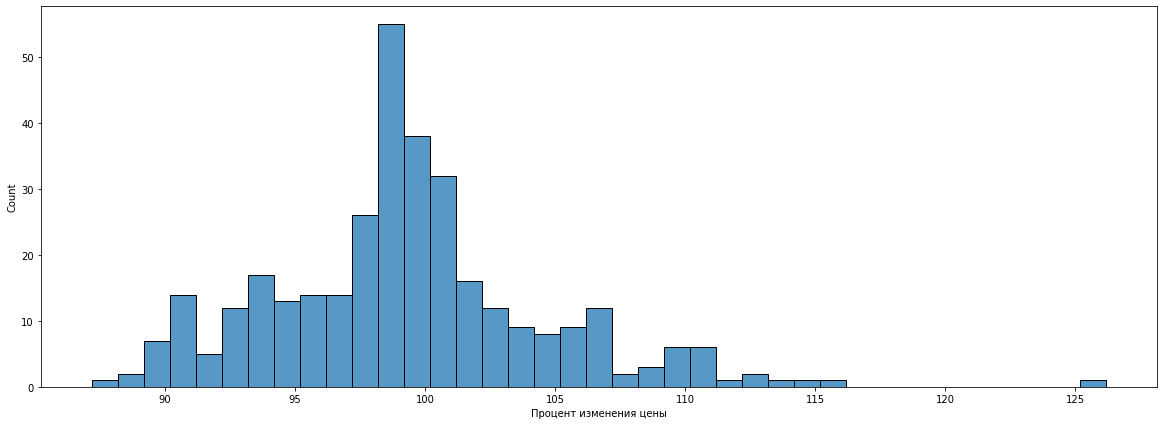

In [ ]:
figsize(20, 7)
sns.histplot(pure_3_inf[('pricechange', 'infl')], binwidth=1)

plt.xlabel('Процент изменения цены')
#plt.title('Rating score')

На графике видно, что подавляющее число самый популярный показатель инфляции = 99% - более 50 из 340. Следующие по популярности показатели - 100 - 101 - 98 - практически означают отсутствие инфляции за такой короткий период с мая по июль. 126% - это выброс. Забегая вперед скажу, что мне не удалось сгруппировать эти коэффициенты по какому-либо признаку. Это просто частота инфляции. Беглый взгляд на сами камни с инфляцией не выявил никаких закономерностей её снижения или увеличения

In [ ]:
# Удаляем аномальные наблюдения
df_three_no_anom = df_three.query('id in @pure_3_inf.index').sort_values(by=['id','date'])

# теперь в качестве цены возьмем последнее значение по времени
df_three_last = df_three_no_anom.groupby('id').agg('last').reset_index()

# соединяем результаты с камнями с одной датой и 2-мя и 3-мя, приведёнными по последней дате
df = pd.concat([df_one, df_three_last]).reset_index(drop=True)

In [ ]:
df

,fluor,symmetry,platform,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,x,depth_perc,y,count
0,NONE,EX,jamesallen,PS,D,SI2,NaN,EX,14224443,202205,9120.0,1.51,6039.74,10.67,6.23,59.0,3.67570,1
1,NONE,VG,jamesallen,EM,K,SI2,NaN,VG,12902293,202205,1390.0,0.91,1527.47,6.30,4.58,71.0,3.25180,1
2,NONE,VG,jamesallen,PS,J,VS1,NaN,VG,12771762,202207,15990.0,2.27,7044.05,11.66,7.26,62.2,4.51572,1
3,MED,EX,jamesallen,RD,J,SI2,EX,EX,14584509,202205,3700.0,1.01,3663.37,6.37,6.42,62.0,3.98040,1
4,NONE,EX,jamesallen,RD,G,SI1,EX,EX,14773748,202206,7170.0,1.00,7170.00,6.30,6.35,63.7,4.04495,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111952,NONE,VG,jamesallen,RD,K,SI1,EX,EX,14871587,202207,2470.0,0.90,2744.44,6.06,6.13,63.0,3.86190,3
111953,NONE,VG,jamesallen,RD,K,VS2,VG,EX,14879009,202207,4840.0,1.20,4033.33,6.65,6.70,63.0,4.22100,3
111954,FNT,EX,jamesallen,OV,H,SI2,None,EX,14879337,202207,5980.0,1.50,3986.67,8.76,6.44,62.0,3.99280,3
111955,FNT,VG,jamesallen,PS,D,SI1,None,VG,14887540,202207,3590.0,0.90,3988.89,7.76,5.19,66.0,3.42540,3


In [ ]:
# избавляемся от вспомогательных столбцов
df = df.drop(columns = 'count')
df

,fluor,symmetry,platform,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,x,depth_perc,y
0,NONE,EX,jamesallen,PS,D,SI2,NaN,EX,14224443,202205,9120.0,1.51,6039.74,10.67,6.23,59.0,3.67570
1,NONE,VG,jamesallen,EM,K,SI2,NaN,VG,12902293,202205,1390.0,0.91,1527.47,6.30,4.58,71.0,3.25180
2,NONE,VG,jamesallen,PS,J,VS1,NaN,VG,12771762,202207,15990.0,2.27,7044.05,11.66,7.26,62.2,4.51572
3,MED,EX,jamesallen,RD,J,SI2,EX,EX,14584509,202205,3700.0,1.01,3663.37,6.37,6.42,62.0,3.98040
4,NONE,EX,jamesallen,RD,G,SI1,EX,EX,14773748,202206,7170.0,1.00,7170.00,6.30,6.35,63.7,4.04495
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111952,NONE,VG,jamesallen,RD,K,SI1,EX,EX,14871587,202207,2470.0,0.90,2744.44,6.06,6.13,63.0,3.86190
111953,NONE,VG,jamesallen,RD,K,VS2,VG,EX,14879009,202207,4840.0,1.20,4033.33,6.65,6.70,63.0,4.22100
111954,FNT,EX,jamesallen,OV,H,SI2,None,EX,14879337,202207,5980.0,1.50,3986.67,8.76,6.44,62.0,3.99280
111955,FNT,VG,jamesallen,PS,D,SI1,None,VG,14887540,202207,3590.0,0.90,3988.89,7.76,5.19,66.0,3.42540


In [ ]:
# проверим, что остались только последние значения по дате, удалим лишний столбец
df = df.drop(columns = 'platform')
df.set_index(['id', 'date'])

,,fluor,symmetry,shape,color,clarity,cut,polish,price,carat,price_per_carat,z,x,depth_perc,y
id,date,,,,,,,,,,,,,,
14224443,202205,NONE,EX,PS,D,SI2,NaN,EX,9120.0,1.51,6039.74,10.67,6.23,59.0,3.67570
12902293,202205,NONE,VG,EM,K,SI2,NaN,VG,1390.0,0.91,1527.47,6.30,4.58,71.0,3.25180
12771762,202207,NONE,VG,PS,J,VS1,NaN,VG,15990.0,2.27,7044.05,11.66,7.26,62.2,4.51572
14584509,202205,MED,EX,RD,J,SI2,EX,EX,3700.0,1.01,3663.37,6.37,6.42,62.0,3.98040
14773748,202206,NONE,EX,RD,G,SI1,EX,EX,7170.0,1.00,7170.00,6.30,6.35,63.7,4.04495
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14871587,202207,NONE,VG,RD,K,SI1,EX,EX,2470.0,0.90,2744.44,6.06,6.13,63.0,3.86190
14879009,202207,NONE,VG,RD,K,VS2,VG,EX,4840.0,1.20,4033.33,6.65,6.70,63.0,4.22100
14879337,202207,FNT,EX,OV,H,SI2,None,EX,5980.0,1.50,3986.67,8.76,6.44,62.0,3.99280


In [ ]:
# начинаем избавляться от сильно коррелирующих фичей например: x / y = depth_perc
df = df.drop(columns = 'x')
df

,fluor,symmetry,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,depth_perc,y
0,NONE,EX,PS,D,SI2,NaN,EX,14224443,202205,9120.0,1.51,6039.74,10.67,59.0,3.67570
1,NONE,VG,EM,K,SI2,NaN,VG,12902293,202205,1390.0,0.91,1527.47,6.30,71.0,3.25180
2,NONE,VG,PS,J,VS1,NaN,VG,12771762,202207,15990.0,2.27,7044.05,11.66,62.2,4.51572
3,MED,EX,RD,J,SI2,EX,EX,14584509,202205,3700.0,1.01,3663.37,6.37,62.0,3.98040
4,NONE,EX,RD,G,SI1,EX,EX,14773748,202206,7170.0,1.00,7170.00,6.30,63.7,4.04495
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111952,NONE,VG,RD,K,SI1,EX,EX,14871587,202207,2470.0,0.90,2744.44,6.06,63.0,3.86190
111953,NONE,VG,RD,K,VS2,VG,EX,14879009,202207,4840.0,1.20,4033.33,6.65,63.0,4.22100
111954,FNT,EX,OV,H,SI2,None,EX,14879337,202207,5980.0,1.50,3986.67,8.76,62.0,3.99280
111955,FNT,VG,PS,D,SI1,None,VG,14887540,202207,3590.0,0.90,3988.89,7.76,66.0,3.42540


In [ ]:
df = df.drop(columns = 'y')
df

,fluor,symmetry,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,depth_perc
0,NONE,EX,PS,D,SI2,NaN,EX,14224443,202205,9120.0,1.51,6039.74,10.67,59.0
1,NONE,VG,EM,K,SI2,NaN,VG,12902293,202205,1390.0,0.91,1527.47,6.30,71.0
2,NONE,VG,PS,J,VS1,NaN,VG,12771762,202207,15990.0,2.27,7044.05,11.66,62.2
3,MED,EX,RD,J,SI2,EX,EX,14584509,202205,3700.0,1.01,3663.37,6.37,62.0
4,NONE,EX,RD,G,SI1,EX,EX,14773748,202206,7170.0,1.00,7170.00,6.30,63.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111952,NONE,VG,RD,K,SI1,EX,EX,14871587,202207,2470.0,0.90,2744.44,6.06,63.0
111953,NONE,VG,RD,K,VS2,VG,EX,14879009,202207,4840.0,1.20,4033.33,6.65,63.0
111954,FNT,EX,OV,H,SI2,None,EX,14879337,202207,5980.0,1.50,3986.67,8.76,62.0
111955,FNT,VG,PS,D,SI1,None,VG,14887540,202207,3590.0,0.90,3988.89,7.76,66.0


In [ ]:
df['cut'].nunique(), df['polish'].nunique()

(3, 3)

In [ ]:
# в этих столбцах всего по 3 значения, которые можно условно заменить цифрами
str_num_cols = ["cut", "polish"]
df[str_num_cols] = df[str_num_cols].replace({'VG': 1,
                                             'EX': 2,
                                             'G': 3,
                                             None: 0})

In [ ]:
# проверим, сменился ли тип данных столбца
df['cut'].dtypes

dtype('int64')

In [ ]:
df['polish'].dtypes

dtype('int64')

In [ ]:
# df['fluor']: в этом столбце тоже 3 уникальных значения и много пустых, всё заменим цифрами
str_num_cols1 = ['fluor']
df[str_num_cols1] = df[str_num_cols1].replace({'MED': 1,
                                             'STG': 2,
                                             'FNT': 3,
                                             'NONE': 0})
df

,fluor,symmetry,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,depth_perc
0,0.0,EX,PS,D,SI2,0,2,14224443,202205,9120.0,1.51,6039.74,10.67,59.0
1,0.0,VG,EM,K,SI2,0,1,12902293,202205,1390.0,0.91,1527.47,6.30,71.0
2,0.0,VG,PS,J,VS1,0,1,12771762,202207,15990.0,2.27,7044.05,11.66,62.2
3,1.0,EX,RD,J,SI2,2,2,14584509,202205,3700.0,1.01,3663.37,6.37,62.0
4,0.0,EX,RD,G,SI1,2,2,14773748,202206,7170.0,1.00,7170.00,6.30,63.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111952,0.0,VG,RD,K,SI1,2,2,14871587,202207,2470.0,0.90,2744.44,6.06,63.0
111953,0.0,VG,RD,K,VS2,1,2,14879009,202207,4840.0,1.20,4033.33,6.65,63.0
111954,3.0,EX,OV,H,SI2,0,2,14879337,202207,5980.0,1.50,3986.67,8.76,62.0
111955,3.0,VG,PS,D,SI1,0,1,14887540,202207,3590.0,0.90,3988.89,7.76,66.0


In [ ]:
df.select_dtypes(object)

,symmetry,shape,color,clarity
0,EX,PS,D,SI2
1,VG,EM,K,SI2
2,VG,PS,J,VS1
3,EX,RD,J,SI2
4,EX,RD,G,SI1
...,...,...,...,...
111952,VG,RD,K,SI1
111953,VG,RD,K,VS2
111954,EX,OV,H,SI2
111955,VG,PS,D,SI1


In [ ]:
str_num_cols2 = ['symmetry']
df[str_num_cols2] = df[str_num_cols2].replace({'EX': 1,
                                             'VG': 2,
                                             'G': 3,
                                             'No': 0})
df

,fluor,symmetry,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,depth_perc
0,0.0,1,PS,D,SI2,0,2,14224443,202205,9120.0,1.51,6039.74,10.67,59.0
1,0.0,2,EM,K,SI2,0,1,12902293,202205,1390.0,0.91,1527.47,6.30,71.0
2,0.0,2,PS,J,VS1,0,1,12771762,202207,15990.0,2.27,7044.05,11.66,62.2
3,1.0,1,RD,J,SI2,2,2,14584509,202205,3700.0,1.01,3663.37,6.37,62.0
4,0.0,1,RD,G,SI1,2,2,14773748,202206,7170.0,1.00,7170.00,6.30,63.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111952,0.0,2,RD,K,SI1,2,2,14871587,202207,2470.0,0.90,2744.44,6.06,63.0
111953,0.0,2,RD,K,VS2,1,2,14879009,202207,4840.0,1.20,4033.33,6.65,63.0
111954,3.0,1,OV,H,SI2,0,2,14879337,202207,5980.0,1.50,3986.67,8.76,62.0
111955,3.0,2,PS,D,SI1,0,1,14887540,202207,3590.0,0.90,3988.89,7.76,66.0


Цены на бриллианты достаточно сильно меняются, попробуйте вычислить коэффициент инфляции и привести цены к последнему месяцу. Стоит учесть, что цены на все бриллианты не изменяются синхронно, то есть изменение в определенных группах может быть разным.

*Определите эти группы и рассчитайте коэффициенты инфляции для каждой из них. Подправьте цены на эти коэффициенты и создайте новую переменную.*

In [ ]:
categories = ['clarity', 'carat'] #укажите по каким группам определять инфляцию (к примеру можно добавить каратную группу)

df_index = df.groupby(['date'] + categories)[['price_per_carat']]\
             .mean()\
             .reset_index() # индекс цен

date_max = df_index.date.max()


df_index = df_index.merge(df_index.query('date == @date_max')[categories + ['price_per_carat']]\
                          .rename(columns={'price_per_carat': 'price_per_carat_max'}), 
                          on=categories, how='outer') # сопоставляем группы с максимальной датой

df_index['inflation'] = df_index.price_per_carat_max / df_index.price_per_carat # вычисляем инфляцию

df_with_inf = df.merge(df_index[['date'] + categories + ['inflation']], 
                        on=['date'] + categories, how='left') # соединяем все в одной таблице

In [ ]:
# пустые значения инфляции заменим нулями
df_with_inf[df_with_inf.inflation.isnull()]

,fluor,symmetry,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,depth_perc,inflation
91,0.0,1,RD,H,SI2,1,1,15104927,202206,21940.0,2.44,8991.80,8.57,61.3,NaN
377,0.0,1,RD,G,SI1,2,2,10853983,202206,89950.0,4.15,21674.70,10.17,62.9,NaN
833,3.0,1,RD,K,IF,2,2,14858668,202206,13790.0,1.77,7790.96,7.71,61.5,NaN
977,1.0,3,CUSH,D,VS2,3,1,12036059,202205,47020.0,3.74,12572.19,9.39,69.0,NaN
997,0.0,1,RD,F,VVS2,2,2,14565876,202205,286730.0,5.28,54304.92,11.12,62.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111451,1.0,2,PS,I,SI1,0,2,10121874,202206,322050.0,11.88,27108.59,19.97,62.0,NaN
111454,2.0,1,RD,D,IF,2,2,12092430,202205,21360.0,1.47,14530.61,7.26,62.0,NaN
111508,3.0,2,CUSH,K,SI1,1,2,13898541,202205,48500.0,5.04,9623.02,10.33,67.0,NaN
111522,0.0,1,RD,J,VS1,2,2,14006611,202205,57990.0,4.51,12858.09,10.39,63.0,NaN


In [ ]:
df_with_inf_1 = df_with_inf.copy()
df_with_inf_1.inflation = df_with_inf.inflation.fillna(0)

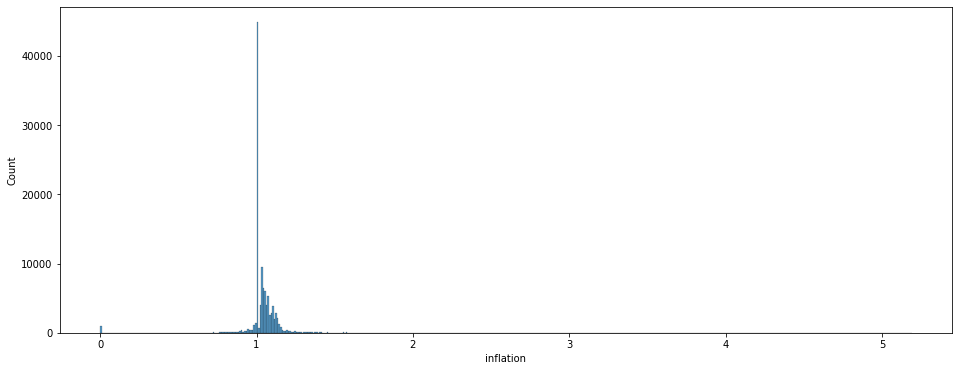

In [ ]:
figsize(16, 6)
sns.histplot(df_with_inf_1['inflation'], binwidth= 0.01)

In [ ]:
df_with_inf_1['inflation'].describe()

count    111957.000000
mean          1.034494
std           0.156750
min           0.000000
25%           1.000000
50%           1.026186
75%           1.070669
max           5.185603
Name: inflation, dtype: float64

Опять вылезли отклонения, потому что мы взяли группы по каратам и по чистоте, а среди данных были камни с одним лишь вхождением по дате без фактической инфляции. Максимальный коэффициент 5,18 вообще значит увеличение цены в пять раз за два всего-то месяца.

Text(0.5, 1.0, 'Коэффициент инфляции по чистоте и каратности')

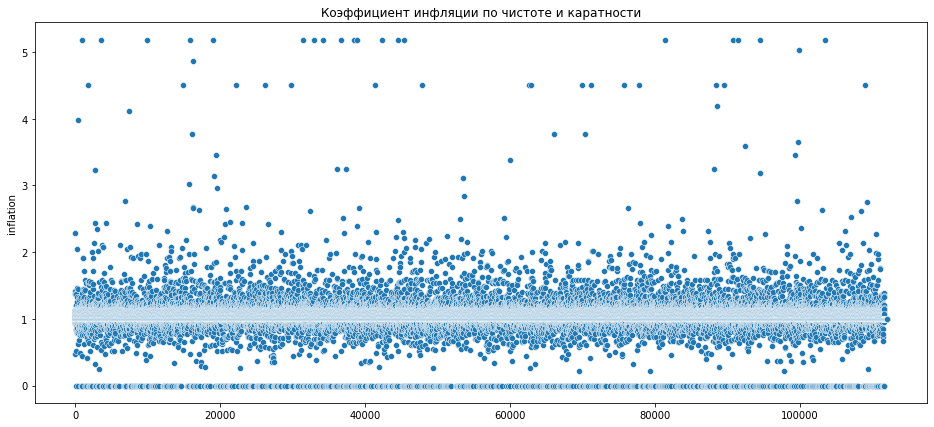

In [ ]:
figsize(16, 7)
sns.scatterplot(data=df_with_inf_1, y=df_with_inf_1.inflation, x=df_with_inf_1.index)
plt.title('Коэффициент инфляции по чистоте и каратности')

In [ ]:
df_with_inf_1

,fluor,symmetry,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,depth_perc,inflation
0,0.0,1,PS,D,SI2,0,2,14224443,202205,9120.0,1.51,6039.74,10.67,59.0,1.073975
1,0.0,2,EM,K,SI2,0,1,12902293,202205,1390.0,0.91,1527.47,6.30,71.0,1.032356
2,0.0,2,PS,J,VS1,0,1,12771762,202207,15990.0,2.27,7044.05,11.66,62.2,1.000000
3,1.0,1,RD,J,SI2,2,2,14584509,202205,3700.0,1.01,3663.37,6.37,62.0,1.040040
4,0.0,1,RD,G,SI1,2,2,14773748,202206,7170.0,1.00,7170.00,6.30,63.7,1.031654
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111952,0.0,2,RD,K,SI1,2,2,14871587,202207,2470.0,0.90,2744.44,6.06,63.0,1.000000
111953,0.0,2,RD,K,VS2,1,2,14879009,202207,4840.0,1.20,4033.33,6.65,63.0,1.000000
111954,3.0,1,OV,H,SI2,0,2,14879337,202207,5980.0,1.50,3986.67,8.76,62.0,1.000000
111955,3.0,2,PS,D,SI1,0,1,14887540,202207,3590.0,0.90,3988.89,7.76,66.0,1.000000


In [ ]:
# сортировка по инфляции
df_with_inf_1.sort_values(by = ['inflation'], ascending= False)

,fluor,symmetry,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,depth_perc,inflation
103367,0.0,1,RD,J,VS1,2,2,14787801,202206,11630.0,1.53,7601.31,7.44,60.2,5.185603
94422,0.0,2,RAD,H,VS1,0,2,8301026,202206,10320.0,1.53,6745.10,6.32,70.2,5.185603
91427,0.0,1,RD,H,VS1,2,2,13888714,202206,16260.0,1.53,10627.45,7.40,61.4,5.185603
38867,0.0,1,RD,G,VS1,2,2,14956493,202206,19920.0,1.53,13019.61,7.37,61.1,5.185603
44553,2.0,2,CUSH,J,VS1,1,2,14740772,202206,6140.0,1.53,4013.07,7.11,73.5,5.185603
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87314,0.0,1,RD,D,VS1,2,2,757707,202206,104600.0,3.24,32283.95,9.47,61.6,0.000000
17752,3.0,2,EM,D,FL,0,2,14095761,202205,5820.0,0.91,6395.60,6.21,61.0,0.000000
71436,0.0,1,RAD,J,FL,0,2,14088688,202206,33730.0,3.06,11022.88,9.14,71.1,0.000000
77066,0.0,1,CUSH,E,VS1,2,2,13720862,202205,60370.0,3.11,19411.58,8.34,67.0,0.000000


In [ ]:
# в новом столбце предскажем цены с учётом инфляции перед октябрём 2022
df_with_inf_1['price_202209'] = round(df_with_inf_1['price_per_carat'] * df_with_inf_1['inflation'], 2)
df_with_inf_1

,fluor,symmetry,shape,color,clarity,cut,polish,id,date,price,carat,price_per_carat,z,depth_perc,inflation,price_202209
0,0.0,1,PS,D,SI2,0,2,14224443,202205,9120.0,1.51,6039.74,10.67,59.0,1.073975,6486.53
1,0.0,2,EM,K,SI2,0,1,12902293,202205,1390.0,0.91,1527.47,6.30,71.0,1.032356,1576.89
2,0.0,2,PS,J,VS1,0,1,12771762,202207,15990.0,2.27,7044.05,11.66,62.2,1.000000,7044.05
3,1.0,1,RD,J,SI2,2,2,14584509,202205,3700.0,1.01,3663.37,6.37,62.0,1.040040,3810.05
4,0.0,1,RD,G,SI1,2,2,14773748,202206,7170.0,1.00,7170.00,6.30,63.7,1.031654,7396.96
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111952,0.0,2,RD,K,SI1,2,2,14871587,202207,2470.0,0.90,2744.44,6.06,63.0,1.000000,2744.44
111953,0.0,2,RD,K,VS2,1,2,14879009,202207,4840.0,1.20,4033.33,6.65,63.0,1.000000,4033.33
111954,3.0,1,OV,H,SI2,0,2,14879337,202207,5980.0,1.50,3986.67,8.76,62.0,1.000000,3986.67
111955,3.0,2,PS,D,SI1,0,1,14887540,202207,3590.0,0.90,3988.89,7.76,66.0,1.000000,3988.89


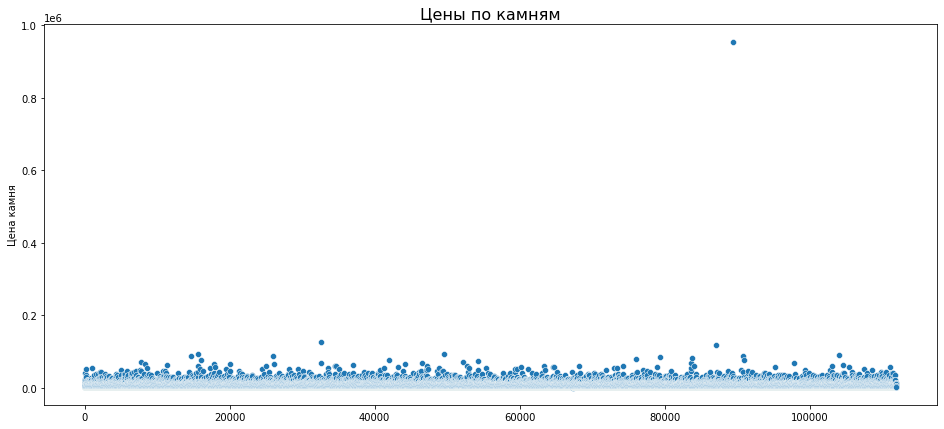

In [ ]:
# Посмотрим график цен по всем камням
figsize=(16, 5)
plt.ylabel("Цена камня")
plt.title("Цены по камням", size=16)
sns.scatterplot(data=df_with_inf_1, y=df_with_inf_1.price_per_carat, x=df_with_inf_1.index)

Цены по камням имеют выбросы. Но касаемо бриллиантов как предметов роскоши, разница в ценах не является аномалией, это может быть уникальный камень по форме или чистоте или цвету и др.

### Задание 2: Модель

Определите функцию потерь (MSE или MAE) и аргументируйте выбор.
Попробуйте сделать baseline.
Используйте LableEncoder для категориальных фичей и **постройте линейную модель**.

In [ ]:
# избавимся от столбцов, в которых больше десяти параметров
df.drop(columns=df.select_dtypes(object).nunique()[df.select_dtypes(object).nunique() >= 10].index, inplace=True)
df

,fluor,symmetry,clarity,cut,polish,id,date,price,carat,price_per_carat,z,depth_perc
0,0.0,1,SI2,0,2,14224443,202205,9120.0,1.51,6039.74,10.67,59.0
1,0.0,2,SI2,0,1,12902293,202205,1390.0,0.91,1527.47,6.30,71.0
2,0.0,2,VS1,0,1,12771762,202207,15990.0,2.27,7044.05,11.66,62.2
3,1.0,1,SI2,2,2,14584509,202205,3700.0,1.01,3663.37,6.37,62.0
4,0.0,1,SI1,2,2,14773748,202206,7170.0,1.00,7170.00,6.30,63.7
...,...,...,...,...,...,...,...,...,...,...,...,...
111952,0.0,2,SI1,2,2,14871587,202207,2470.0,0.90,2744.44,6.06,63.0
111953,0.0,2,VS2,1,2,14879009,202207,4840.0,1.20,4033.33,6.65,63.0
111954,3.0,1,SI2,0,2,14879337,202207,5980.0,1.50,3986.67,8.76,62.0
111955,3.0,2,SI1,0,1,14887540,202207,3590.0,0.90,3988.89,7.76,66.0


Отвалились два столбца: shape и color

In [ ]:
# посмотрим, какие значения содержатся в cтолбце clarity
df['clarity'].value_counts()

SI2     24341
SI1     23020
VS2     20650
VS1     18326
VVS2    11369
VVS1     8008
I1       3366
IF       2685
FL        192
Name: clarity, dtype: int64

In [ ]:
# заменим строковые значения цифровыми
str_num_cols_1 = ['clarity']
df[str_num_cols_1] = df[str_num_cols_1].replace({'SI2': 1,
                                             'SI1': 2,
                                             'VS1': 3,
                                             'VS2': 4,
                                             'VVS1': 5,
                                             'VVS2': 6,
                                             'I1': 7,
                                             'IF': 8,
                                             'FL': 9})
df

,fluor,symmetry,clarity,cut,polish,id,date,price,carat,price_per_carat,z,depth_perc
0,0.0,1,1,0,2,14224443,202205,9120.0,1.51,6039.74,10.67,59.0
1,0.0,2,1,0,1,12902293,202205,1390.0,0.91,1527.47,6.30,71.0
2,0.0,2,3,0,1,12771762,202207,15990.0,2.27,7044.05,11.66,62.2
3,1.0,1,1,2,2,14584509,202205,3700.0,1.01,3663.37,6.37,62.0
4,0.0,1,2,2,2,14773748,202206,7170.0,1.00,7170.00,6.30,63.7
...,...,...,...,...,...,...,...,...,...,...,...,...
111952,0.0,2,2,2,2,14871587,202207,2470.0,0.90,2744.44,6.06,63.0
111953,0.0,2,4,1,2,14879009,202207,4840.0,1.20,4033.33,6.65,63.0
111954,3.0,1,1,0,2,14879337,202207,5980.0,1.50,3986.67,8.76,62.0
111955,3.0,2,2,0,1,14887540,202207,3590.0,0.90,3988.89,7.76,66.0


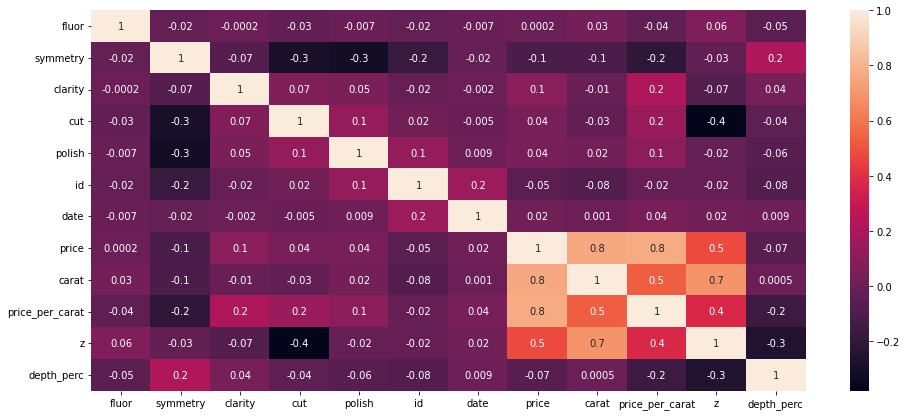

In [ ]:
# посмотрим на хитмэп корреляции признаков

sns.heatmap(df.corr(), annot = True, fmt='.1g')


В основном, признаки не коррелируют друг с другом, кроме, понятно, цена с каратом и ценой за карат. Интересно, что признак z немного коррелирует с каратом. Вспомним, Z - это диаметр, ширина, т.е. чем больше каратность, тем больше диаметр, в зависимости от формы, логично.

Строковых столбцов больше не оказалось

In [ ]:
# избавимся от строк с пустыми значениями
print(df.isna().sum())
df = df.dropna()

fluor              3
symmetry           0
clarity            0
cut                0
polish             0
id                 0
date               0
price              0
carat              0
price_per_carat    0
z                  0
depth_perc         0
dtype: int64


In [ ]:
# 3 строки содержали пустые значения, они удалились
df

,fluor,symmetry,clarity,cut,polish,id,date,price,carat,price_per_carat,z,depth_perc
0,0.0,1,1,0,2,14224443,202205,9120.0,1.51,6039.74,10.67,59.0
1,0.0,2,1,0,1,12902293,202205,1390.0,0.91,1527.47,6.30,71.0
2,0.0,2,3,0,1,12771762,202207,15990.0,2.27,7044.05,11.66,62.2
3,1.0,1,1,2,2,14584509,202205,3700.0,1.01,3663.37,6.37,62.0
4,0.0,1,2,2,2,14773748,202206,7170.0,1.00,7170.00,6.30,63.7
...,...,...,...,...,...,...,...,...,...,...,...,...
111952,0.0,2,2,2,2,14871587,202207,2470.0,0.90,2744.44,6.06,63.0
111953,0.0,2,4,1,2,14879009,202207,4840.0,1.20,4033.33,6.65,63.0
111954,3.0,1,1,0,2,14879337,202207,5980.0,1.50,3986.67,8.76,62.0
111955,3.0,2,2,0,1,14887540,202207,3590.0,0.90,3988.89,7.76,66.0


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import max_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

# определим таргет
X = df.drop(columns=["price_per_carat"])
y = df["price_per_carat"]

# разделим на тренировочную и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=13)

In [ ]:
model_lr = LinearRegression()

# Обучим модель
model_lr.fit(X_train, y_train)


LinearRegression()

In [ ]:
y_pred_test_lr = model_lr.predict(X_test)

In [ ]:
print(y_pred_test_lr)
print(y_test)

[8137.87922036 5494.99466863 5931.83362271 ... 8511.20740287 5707.86328599
 8180.73863455]
8639       9853.33
51424      4306.93
102522     5469.88
99901     21571.43
63591      5755.56
            ...   
58633      4876.24
75019      8246.03
104995     7320.00
61371      4130.00
4195       9040.00
Name: price_per_carat, Length: 33587, dtype: float64


In [ ]:
# Эти функции ошибки показывают максимальную, среднюю по модулю ошибку и процентную ошибку по модулю
print("MAE: ", mean_absolute_error(y_test, y_pred_test_lr))
print("MaxE: ", max_error(y_test, y_pred_test_lr))
print("MAPE: ", mean_absolute_percentage_error(y_test, y_pred_test_lr))

MAE:  1469.9814632645614
MaxE:  93752.48622689814
MAPE:  0.260321954313038


/usr/local/lib/python3.8/dist-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


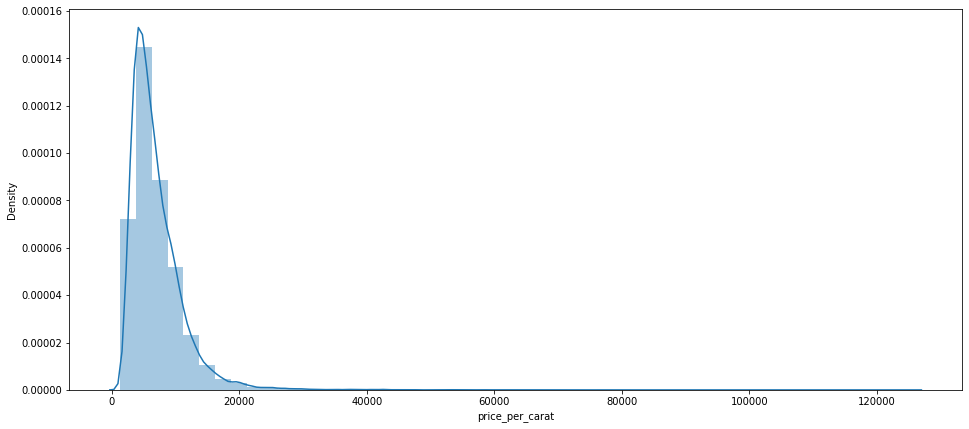

In [ ]:
# график распределения цены за карат на тестовой выборке
sns.distplot(y_test)

/usr/local/lib/python3.8/dist-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


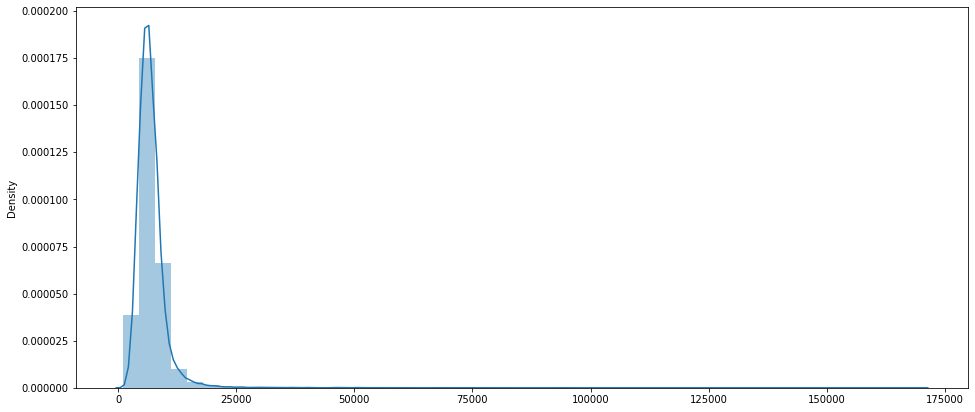

In [ ]:
# график цены за карат предсказанный моделью
sns.distplot(y_pred_test_lr)

***При грубом приближении графики относительно совпадают. Максимальная цена не угадана, мода тоже. Линейная модель, наверно, не может более точно предсказать цену такого сложного товара, как бриллианты. Хотя MAPE ошибка хорошая. Она показывает относительную процентную ошибку к реальным данным***

Теперь попробуйте OHE или TargetEncoder (сравните их).

Нормализуйте данные.

Поработайте с пропусками (обратите внимание на то, что у fluor возможен пропуск значения, а возможно отсутствие флуоресценции)

Покажите, насколько получилось улучшить результат.

In [ ]:
! pip install category_encoders

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 72 kB 940 kB/s 


In [ ]:
from sklearn.preprocessing import OneHotEncoder
from category_encoders import TargetEncoder
from sklearn.preprocessing import StandardScaler

from typing import Tuple, List


def OHE(df: pd.DataFrame, columns: List[str]) -> Tuple[pd.DataFrame, List[str]]:
   
    index = df.index
    one = OneHotEncoder(sparse=False, categories='auto')
    ohe = one.fit_transform(df[columns])
    col_names = one.get_feature_names(input_features = columns)
    df = df.drop(columns, axis=1)
    df = df.reset_index(drop=True)
    df = pd.concat([df, pd.DataFrame(ohe, columns=col_names)], axis = 1)
    df = df.set_index(index)
    return (df, col_names)

scaler = StandardScaler() # Помните, что на тесте делаем только transform

In [ ]:
# определим таргет
X1 = df.drop(columns=["price_per_carat"])
y1 = df["price_per_carat"]
# выделим категории (['fluor', 'symmetry', 'platform', 'clarity', 'cut', 'polish'])
categories = X1.columns[X1.dtypes == object]
# закодируем категориальные колонки с помощью ОНЕ
X1, cat_col = OHE(X1, categories)
# разобьём на тренировочную и валидационную выборку
X_train_1, X_valid_1, y_train_1, y_valid_1 = train_test_split(X1, y1, test_size=0.3, random_state=13)


/usr/local/lib/python3.8/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)


In [ ]:
# Построим линейную модель
model_ohe = LinearRegression()
model_ohe.fit(X_train_1, y_train_1)
y_predict_1 = model_ohe.predict(X_valid_1)
# проверим абсолютную ошибку
mean_absolute_error(y_valid_1, y_predict_1)
# ошибка не изменилась, так как категориальные признаки мы закодировали вручную и теперь кодирование признаков не имеет смысла

1469.9814632645614

In [ ]:
# проверим максимальную ошибку
max_error(y_valid_1, y_predict_1)

93752.48622689814

In [ ]:
# проверим процентную абсолютную ошибку
mean_absolute_percentage_error(y_valid_1, y_predict_1)

0.260321954313038

In [ ]:
# теперь закодируем с помощью TargetEncoder
# выделим таргет
X_tar = df.drop(columns=["price"])
y_tar = df["price"]
# выделим категориальные колонки (['fluor', 'symmetry', 'platform', 'clarity', 'cut', 'polish'])
categorical_cols = X_tar.columns[X_tar.dtypes == object]
# закодируем категориальные колонки
t_enc = TargetEncoder(cols=categorical_cols)
t_enc.fit(X_tar[categorical_cols], y_tar)
X_tar[categorical_cols] = t_enc.transform(X_tar[categorical_cols])
# разобьём на тренировочную и валидационную выборку
X_train_tar, X_valid_tar, y_train_tar, y_valid_tar = train_test_split(X_tar, y_tar, test_size=0.3, random_state=13)

/usr/local/lib/python3.8/dist-packages/category_encoders/target_encoder.py:122: FutureWarning: Default parameter min_samples_leaf will change in version 2.6.See https://github.com/scikit-learn-contrib/category_encoders/issues/327
  warnings.warn("Default parameter min_samples_leaf will change in version 2.6."
/usr/local/lib/python3.8/dist-packages/category_encoders/target_encoder.py:127: FutureWarning: Default parameter smoothing will change in version 2.6.See https://github.com/scikit-learn-contrib/category_encoders/issues/327
  warnings.warn("Default parameter smoothing will change in version 2.6."


In [ ]:
# Построим линейную модель
model_tar = LinearRegression()
model_tar.fit(X_train_tar, y_train_tar)
y_predict_tar = model_tar.predict(X_valid_tar)
# проверим среднеквадратичную ошибку
mean_absolute_error(y_valid_tar, y_predict_tar)
# ошибка увеличилась
# TargetEncoder работает хуже OHЕ

3951.2821756640255

In [ ]:
max_error(y_valid_tar, y_predict_tar)

505394.7867767364

In [ ]:
mean_absolute_percentage_error(y_valid_tar, y_predict_tar)

0.5921029210156794

In [ ]:
# Закодируем с помощью OHE, а затем отнормируем с помощью StandardScaler
# выделим таргет
X1_sc = df.drop(columns=["price_per_carat"])
y1_sc = df["price_per_carat"]
# выделим категориальные колонки (['fluor', 'symmetry', 'clarity', 'cut', 'polish'])
categorical_cols_sc = X1_sc.columns[X1_sc.dtypes == object]
# закодируем категориальные колонки с помощью ОНЕ
X1_sc, cat_col_sc = OHE(X1_sc, categorical_cols_sc)
# разобьём на тренировочную и валидационную выборку
X_train_1_sc, X_test_1_sc, y_train_1_sc, y_test_1_sc = train_test_split(X1_sc, y1_sc, test_size=0.3, random_state=13)

/usr/local/lib/python3.8/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)


In [ ]:
X_train_1_sc_cat = X_train_1_sc[cat_col_sc]
X_train_1_sc_num = X_train_1_sc.drop(columns=cat_col_sc)
X_test_1_sc_cat = X_test_1_sc[cat_col_sc]
X_test_1_sc_num = X_test_1_sc.drop(columns=cat_col_sc)
# задаем модель нормировки
scaler = StandardScaler()
scaler.fit(X_train_1_sc_num, y_train_1_sc)
# нормируем данные
X_train_1_sc_num = pd.DataFrame(scaler.transform(X_train_1_sc_num), index=X_train_1_sc_num.index, columns=X_train_1_sc_num.columns)
X_test_1_sc_num = pd.DataFrame(scaler.transform(X_test_1_sc_num), index=X_test_1_sc_num.index, columns=X_test_1_sc_num.columns)

In [ ]:
# соединяем данные в единый датасет
X_train_normed = pd.concat([X_train_1_sc_num, X_train_1_sc_cat], 1)
X_test_normed = pd.concat([X_test_1_sc_num, X_test_1_sc_cat], 1)

<ipython-input-93-d88384cef7f8>:2: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only
  X_train_normed = pd.concat([X_train_1_sc_num, X_train_1_sc_cat], 1)
<ipython-input-93-d88384cef7f8>:3: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only
  X_test_normed = pd.concat([X_test_1_sc_num, X_test_1_sc_cat], 1)


In [ ]:
X_train_normed.head()

,fluor,symmetry,clarity,cut,polish,id,date,price,carat,z,depth_perc
15041,-0.674716,-0.752654,-1.193924,-1.313107,0.323735,0.430370,-0.050555,-0.369048,-0.511657,-0.208786,0.340066
95615,-0.674716,0.984804,0.400486,-1.313107,-2.757408,0.627876,1.134568,-0.221717,-0.511657,1.345976,-1.365392
43318,-0.674716,0.984804,-0.130984,-1.313107,0.323735,0.267782,1.134568,-0.000720,0.245884,0.135055,1.509522
29373,1.822001,0.984804,-0.130984,0.810688,0.323735,-6.473672,1.134568,0.657489,1.018576,-0.119089,1.314613
101093,-0.674716,-0.752654,-0.662454,0.810688,0.323735,0.521397,1.134568,-0.203061,-0.375299,-0.418081,-0.439572


In [ ]:
# Построим линейную модель после всех преобразований
model_1_sc = LinearRegression()
model_1_sc.fit(X_train_normed, y_train_1_sc)
y_predict_1_sc = model_1_sc.predict(X_test_normed)
# проверим среднеквадратичную ошибку
mean_absolute_error(y_test_1_sc, y_predict_1_sc)

# ошибка примерно такая же, как и без нормализации

1469.981463264866

In [ ]:
max_error(y_test_1_sc, y_predict_1_sc)

93752.48622626292

In [ ]:
mean_absolute_percentage_error(y_test_1_sc, y_predict_1_sc)

0.26032195431256844

In [ ]:
print("MAE линейной регрессии: ", mean_absolute_error(y_test, y_pred_test_lr))
print("MaxE линейной регрессии: ", max_error(y_test, y_pred_test_lr))
print("MAPE линейной регрессии: ", mean_absolute_percentage_error(y_test, y_pred_test_lr))
print("MAE линейной регрессии с OHE: ", mean_absolute_error(y_valid_1, y_predict_1))
print("MaxE линейной регрессии с OHE: ", max_error(y_valid_1, y_predict_1))
print("MAPE линейной регрессии с ОНЕ: ", mean_absolute_percentage_error(y_valid_1, y_predict_1))
print("MAE с TargetEncoder: ", mean_absolute_error(y_valid_tar, y_predict_tar))
print("MaxE с TargetEncoder: ", max_error(y_valid_tar, y_predict_tar))
print("MAPE с TargetEncoder: ", mean_absolute_percentage_error(y_valid_tar, y_predict_tar))
print("MAE с OHE и StandardScaler: ", mean_absolute_error(y_test_1_sc, y_predict_1_sc))
print("MaxE с OHE и StandardScaler: ", max_error(y_test_1_sc, y_predict_1_sc))
print("MAPE с OHE и StandardScaler: ", mean_absolute_percentage_error(y_test_1_sc, y_predict_1_sc))


MAE линейной регрессии:  1469.9814632645614
MaxE линейной регрессии:  93752.48622689814
MAPE линейной регрессии:  0.260321954313038
MAE линейной регрессии с OHE:  1469.9814632645614
MaxE линейной регрессии с OHE:  93752.48622689814
MAPE линейной регрессии с ОНЕ:  0.260321954313038
MAE с TargetEncoder:  3951.2821756640255
MaxE с TargetEncoder:  505394.7867767364
MAPE с TargetEncoder:  0.5921029210156794
MAE с OHE и StandardScaler:  1469.981463264866
MaxE с OHE и StandardScaler:  93752.48622626292
MAPE с OHE и StandardScaler:  0.26032195431256844


Сравните работу выбранной вами линейной модели с KNN

In [ ]:
# сравним с kNN

from sklearn.neighbors import KNeighborsRegressor

model_knn = KNeighborsRegressor()
model_knn.fit(X_train_normed, y_train_1_sc)
y_predict_1_sc_knn = model_knn.predict(X_test_normed)
# проверим среднюю абсолютную ошибку
mean_absolute_error(y_test_1_sc, y_predict_1_sc_knn)

972.6278207044393

In [ ]:
max_error(y_test_1_sc, y_predict_1_sc_knn)

45800.386

In [ ]:
mean_absolute_percentage_error(y_test_1_sc, y_predict_1_sc_knn)

0.17678861566355397

/usr/local/lib/python3.8/dist-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


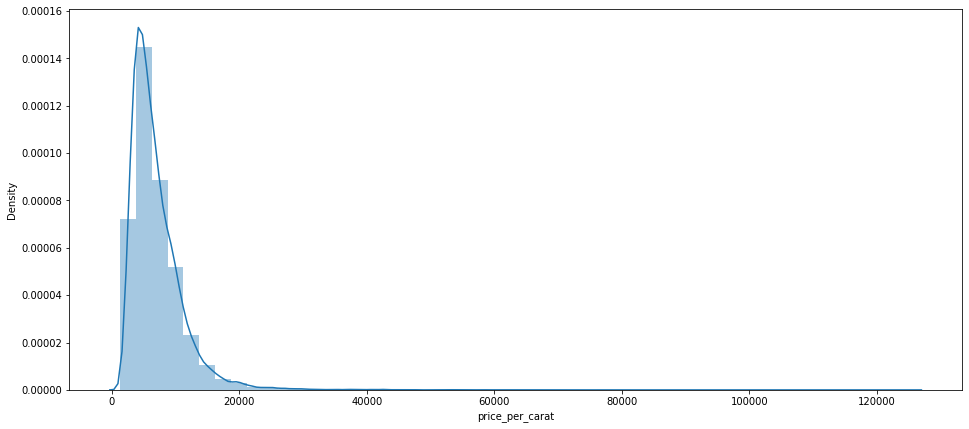

In [ ]:
# график распределения цены за карат на тестовой выборке
sns.distplot(y_test_1_sc)

/usr/local/lib/python3.8/dist-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


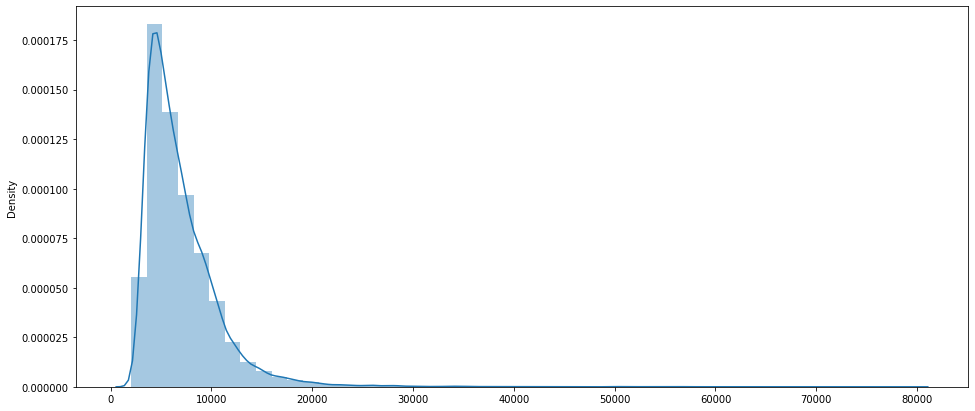

In [ ]:
# график распределения цены за карат на тестовой выборке
sns.distplot(y_predict_1_sc_knn)

Модель KNN работает намного лучше. Так как зависимость цены от каратности или других признаков далека от линейной зависимости. Тут больше зависисмость от ближайших соседей, более мелкие камни берут количеством, дорогих и больших камней мало - штучный товар.



Я выбрала такие метрики, потому что разброс в ценах очень большой и максимальное ошибочное отклонение может показать MaxError, MAPE процентная ошибка может показать ошибку не в целом по выборке, а по позиции, а средняя по модулю MAE без возведения в квадрат, так как числа итак огромные, а количество выбросов не маленькое и имеет значение

## Классификация

Загрузите датасет bodyPerformance

Описание:

https://www.kaggle.com/datasets/kukuroo3/body-performance-data

Загрузим файлы во временное хранилище Colab

In [ ]:
Df = pd.read_csv('bodyPerformance.csv', index_col=0)
Df.head()

,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
age,,,,,,,,,,,
27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


In [ ]:
Df

,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
age,,,,,,,,,,,
27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B
...,...,...,...,...,...,...,...,...,...,...,...
25.0,M,172.1,71.80,16.2,74.0,141.0,35.8,17.4,47.0,198.0,C
21.0,M,179.7,63.90,12.1,74.0,128.0,33.0,1.1,48.0,167.0,D
39.0,M,177.2,80.50,20.1,78.0,132.0,63.5,16.4,45.0,229.0,A


In [ ]:
Df.select_dtypes(object)

,gender,class
age,,
27.0,M,C
25.0,M,A
31.0,M,C
32.0,M,B
28.0,M,B
...,...,...
25.0,M,C
21.0,M,D
39.0,M,A


In [ ]:
Df['gender'].value_counts()

M    8467
F    4926
Name: gender, dtype: int64

In [ ]:
# Преобразуем признак gender как 0 и 1, где 0 - F, 1 - M (этого более, чем достаточно)
Df.gender = Df.gender.apply(lambda x: 1 if x == 'M' else 0)

In [ ]:
Df['class'].value_counts()

C    3349
D    3349
A    3348
B    3347
Name: class, dtype: int64

In [ ]:
Df['class'] = Df['class'].replace({'A': 1, 
                               'B': 2, 
                               'C': 3, 
                               'D': 4})
Df

,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
age,,,,,,,,,,,
27.0,1,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,3
25.0,1,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,1
31.0,1,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,3
32.0,1,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,2
28.0,1,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,2
...,...,...,...,...,...,...,...,...,...,...,...
25.0,1,172.1,71.80,16.2,74.0,141.0,35.8,17.4,47.0,198.0,3
21.0,1,179.7,63.90,12.1,74.0,128.0,33.0,1.1,48.0,167.0,4
39.0,1,177.2,80.50,20.1,78.0,132.0,63.5,16.4,45.0,229.0,1


### Задание 1: Определение гендера

Постройте модель, которая будет определять гендер.

Для этого определите две метрики качества, на которые вы будете смотреть. Аргументируйте свой выбор.

После чего преобразуйте категориальные переменные и постройте модель бинарной классификации на основе линейного классификатора и сравните с KNN.

P.S.: не забудьте про нормализацию.

In [ ]:
# Посмотрим на соотношение классов в нашем датасете
print(f"Всего мужчин в датасете: {(Df['gender'] == 1).sum()}, а женщин: {(Df['gender'] == 0).sum()}")

Всего мужчин в датасете: 8467, а женщин: 4926


Мы видим, что данные не сильно разбалансированы, с ними можно работать

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import f1_score
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler

X = Df.drop(columns=["gender"])
y = Df["gender"]

X_norm = preprocessing.normalize(X)

X_train, X_valid, y_train, y_valid = train_test_split(X_norm, y, test_size=0.25, random_state=13, stratify= y)

scaler = StandardScaler()

In [ ]:
X_valid.shape

(3349, 10)

In [ ]:
y_valid.shape

(3349,)

In [ ]:
scaler.fit(X_train, y_train)

StandardScaler()

In [ ]:
# нормируем данные
X_train_num = pd.DataFrame(scaler.transform(X_train))
X_valid_num = pd.DataFrame(scaler.transform(X_valid))

In [ ]:
X_norm

array([[0.51221583, 0.22367451, 0.06332094, ..., 0.17836883, 0.64510061,
        0.00891844],
       [0.49924007, 0.16883392, 0.04750345, ..., 0.16036196, 0.69288471,
        0.0030257 ],
       [0.54743325, 0.23774941, 0.06126619, ..., 0.1493554 , 0.55170054,
        0.00914421],
       ...,
       [0.51034227, 0.23184285, 0.05788871, ..., 0.12960159, 0.6595281 ,
        0.00288004],
       [0.64273488, 0.25383848, 0.17773093, ..., 0.        , 0.32994604,
        0.01759712],
       [0.52597971, 0.21199548, 0.06254027, ..., 0.16356686, 0.5772948 ,
        0.00962158]])

In [ ]:
# Построим линейную модель
model_lc = LogisticRegression()
model_lc.fit(X_train_num, y_train)
y_predict_lc = model_lc.predict(X_train_num)
y_pred_test_lc = model_lc.predict(X_valid_num)


# посмотрим ошибки ROC AUC и F1
print("ROC AUC: ", roc_auc_score(y_valid, y_pred_test_lc))
print("F1: ", f1_score(y_valid, y_pred_test_lc))

ROC AUC:  0.9800971495438903
F1:  0.9853566367501181


In [ ]:
# Создадим экземпляр класса KNeighborsClassifier с числом ближайших соседей (n_neighbors) равным 5
model_knn = KNeighborsClassifier(n_neighbors = 5)

# Обучим модель
model_knn.fit(X_train_num, y_train)
# Сделаем предсказание на тестовой выборке
y_pred_train_KNN = model_knn.predict(X_train_num)
y_pred_test_KNN  = model_knn.predict(X_valid_num)

In [ ]:
# посмотрим ошибки ROC AUC и F1
print("ROC AUC: ", roc_auc_score(y_valid, y_pred_test_KNN))
print("F1: ", f1_score(y_valid, y_pred_test_KNN))

ROC AUC:  0.9763780297406892
F1:  0.9830188679245284


In [ ]:
# Посмотрим accuracy на обучении и на тесте

print(f"TEST LC:  Accuracy -- {accuracy_score(y_valid, y_pred_test_lc)}")
print(f"TRAIN LC: Accuracy -- {accuracy_score(y_train, y_predict_lc)}")

print(f"TEST KNN:  Accuracy -- {accuracy_score(y_valid, y_pred_test_KNN)}")
print(f"TRAIN KNN: Accuracy -- {accuracy_score(y_train, y_pred_train_KNN)}")

TEST LC:  Accuracy -- 0.981487011048074
TRAIN LC: Accuracy -- 0.9811827956989247
TEST KNN:  Accuracy -- 0.978501045088086
TRAIN KNN: Accuracy -- 0.9860613301473516


В целом бинарную классификацию выполняют хорошо как логистическая реггрессия, так и метод ближайших соседей. Логистическая регрессия лучше с нормировкой в предсказании, чем метод ближайших соседей, хотя ненамного.

### Задание 2: Определение класса

Теперь попробуем построить модель, которая будет предсказывать class физической формы.

Для этого определите метрики качества для задачи мультиклассификации (аргументируйте выбор).

Постройте модель мультиклассовой классификации на основе линейного классификатора и сравните с KNN.

In [ ]:
Df

,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
age,,,,,,,,,,,
27.0,1,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,3
25.0,1,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,1
31.0,1,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,3
32.0,1,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,2
28.0,1,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,2
...,...,...,...,...,...,...,...,...,...,...,...
25.0,1,172.1,71.80,16.2,74.0,141.0,35.8,17.4,47.0,198.0,3
21.0,1,179.7,63.90,12.1,74.0,128.0,33.0,1.1,48.0,167.0,4
39.0,1,177.2,80.50,20.1,78.0,132.0,63.5,16.4,45.0,229.0,1


In [ ]:
from sklearn.metrics import r2_score

X1 = Df.drop(columns=["class"]) # укажите новый таргет
y1 = Df["class"]

X1_norm = preprocessing.normalize(X1, norm='l2')

X_train_c, X_valid_c, y_train_c, y_valid_c = train_test_split(X1_norm, y1, test_size=0.2, random_state=42)

In [ ]:
scaler.fit(X_train_c, y_train_c)

StandardScaler()

In [ ]:
# нормируем данные
X_train_num_c = pd.DataFrame(scaler.transform(X_train_c))
X_valid_num_c = pd.DataFrame(scaler.transform(X_valid_c))

In [ ]:
# Построим линейную модель
model_lc_class = LogisticRegression()
model_lc_class.fit(X_train_num_c, y_train_c)
y_predict_lc_1 = model_lc_class.predict(X_train_num_c)
y_pred_test_lc_1 = model_lc_class.predict(X_valid_num_c)

# посмотрим ошибки r2 и MSE
print("R2: ", r2_score(y_valid_c, y_pred_test_lc_1))
print("MSE: ", mean_squared_error(y_valid_c, y_pred_test_lc_1))

R2:  0.44531095781164864
MSE:  0.7047405748413588


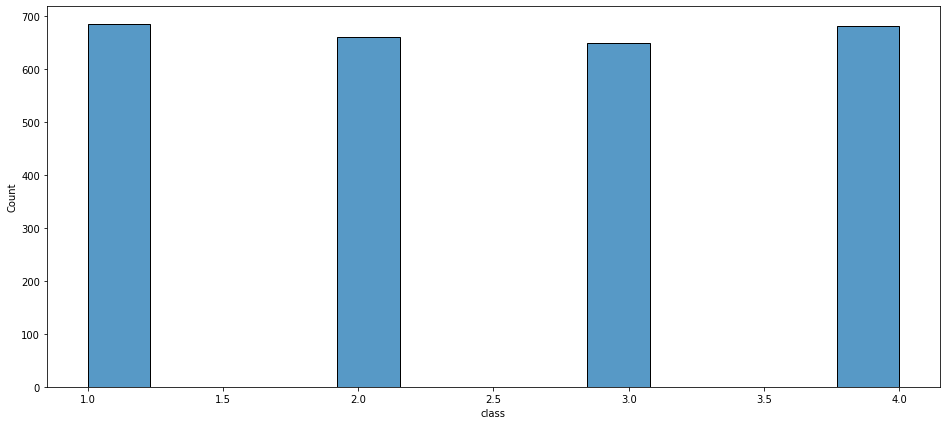

In [ ]:
# график классов тестовой части
sns.histplot(y_valid_c)

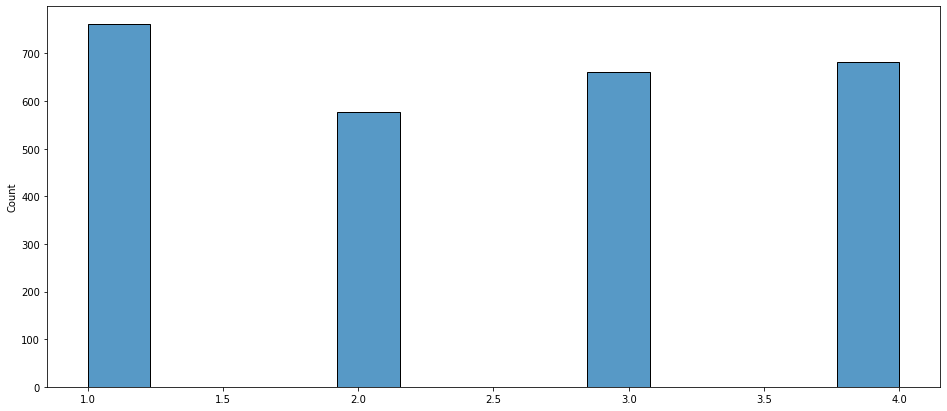

In [ ]:
# график классов предсказанных моделью
sns.histplot(y_pred_test_lc_1)

In [ ]:
# Создадим экземпляр класса KNeighborsClassifier с числом ближайших соседей (n_neighbors) равным 3
model_knn_class = KNeighborsClassifier(n_neighbors = 3)

# Обучим модель
model_knn_class.fit(X_train_num_c, y_train_c)
# Сделаем предсказание на тестовой выборке
y_pred_train_KNN_c = model_knn_class.predict(X_train_num_c)
y_pred_test_KNN_c = model_knn_class.predict(X_valid_num_c)

In [ ]:
# посмотрим ошибки r2 и MSE
print("R2 KNN: ", r2_score(y_valid_c, y_pred_test_KNN_c))
print("MSE KNN: ", mean_squared_error(y_valid_c, y_pred_test_KNN_c))

R2 KNN:  0.3154526121298419
MSE KNN:  0.8697275102650243


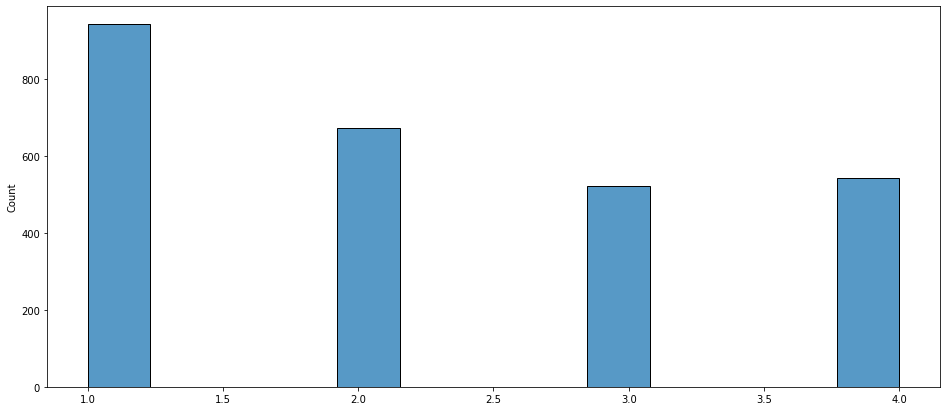

In [ ]:
# график классов предсказанных моделью
sns.histplot(y_pred_test_KNN_c)

In [ ]:
# посмотрим ошибки r2 и MSE в сравнении
print("R2 lr: ", r2_score(y_valid_c, y_pred_test_lc_1))
print("R2 KNN: ", r2_score(y_valid_c, y_pred_test_KNN_c))
print("MSE lr: ", mean_squared_error(y_valid_c, y_pred_test_lc_1))
print("MSE KNN: ", mean_squared_error(y_valid_c, y_pred_test_KNN_c))
print("Accuracy lr: ", accuracy_score(y_valid_c, y_pred_test_lc_1))
print("Accuracy KNN: ", accuracy_score(y_valid_c, y_pred_test_KNN_c))

R2 lr:  0.44531095781164864
R2 KNN:  0.3154526121298419
MSE lr:  0.7047405748413588
MSE KNN:  0.8697275102650243
Accuracy lr:  0.5845464725643897
Accuracy KNN:  0.5453527435610303


Опять метод ближайших соседей хуже сработал в определении класса физической формы чем логистическая регрессия. С базой данных нужно было больше поработать в отладке, нормировании, хотя база данных не сложная и не огромная. Метрики были выбраны MSE как средняя ошибка и R2 - нормированная средняя ошибка, и точность. Более показательным оказался график предсказаний, где наглядно видно распределение по классам тренировочной части и после работы двух моделей предсказания. Точность попадания показывает метрика Accuracy